In [1]:
import pandas as pd
import json
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data_path = "data/fashion_products_dataset.json"

# Load the JSON data from the file
with open(data_path) as fp:
    data = json.load(fp)

# Print the datatype of the loaded data
print("Datatype of the loaded data:", type(data))

# Print the number of products in the dataset and the first product if the data is a list
if isinstance(data, list):
    print("Number of products in the dataset:", len(data))
    print("First product in the dataset:", data[0])

Datatype of the loaded data: <class 'list'>
Number of products in the dataset: 28080
First product in the dataset: {'_id': 'fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a', 'actual_price': '2,999', 'average_rating': '3.9', 'brand': 'York', 'category': 'Clothing and Accessories', 'crawled_at': 1612987911000, 'description': 'Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India', 'discount': '69% off', 'images': ['https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-1005combo2-yorker-original-imafczg3xfh5qqd4.jpeg?q=70', 'https://rukminim1.flixcart.com/image/128/128/jr58l8w0/track-pant/w/d/a/l-1005combo8-yorker-original-imafczg3pgtxgraq.jpeg?q=70'], 'out_of_stock': False, 'pid': 'TKPFCZ9EA7H5FYZH', 'product_details': [{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid

In [3]:
# Create a DataFrame from the loaded data
df = pd.DataFrame(data)

# Display the shape of the DataFrame, the first few rows, and the column names
print("Dataset shape:", df.shape)
display(df.head())
print("Column names:", df.columns.tolist())


Dataset shape: (28080, 17)


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,1612987911000,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
3,3f3f97bb-5faf-57df-a9ff-1af24e2b1045,"2,999",3.9,York,Clothing and Accessories,1612987913000,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,911,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
4,750caa3d-6264-53ca-8ce1-94118a1d8951,"2,999",3.9,York,Clothing and Accessories,1612987913000,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,943,Bottomwear,"Solid Women Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...


Column names: ['_id', 'actual_price', 'average_rating', 'brand', 'category', 'crawled_at', 'description', 'discount', 'images', 'out_of_stock', 'pid', 'product_details', 'seller', 'selling_price', 'sub_category', 'title', 'url']


In [4]:
# Display information about the DataFrame
df.info()

# Check for missing values in the DataFrame
display(df.isnull().sum())

# Check for duplicate product IDs in the DataFrame
print("Duplicate pids:", df["pid"].duplicated().sum())

expected_fields = ["pid", "title", "description", "brand", "category",
                   "sub_category", "product_details", "seller", "out_of_stock",
                   "selling_price", "discount", "actual_price", "average_rating", "url"]

# Check for missing columns in the DataFrame
print("Missing columns:", set(expected_fields) - set(df.columns))

<class 'pandas.DataFrame'>
RangeIndex: 28080 entries, 0 to 28079
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   _id              28080 non-null  str   
 1   actual_price     28080 non-null  str   
 2   average_rating   28080 non-null  str   
 3   brand            28080 non-null  str   
 4   category         28080 non-null  str   
 5   crawled_at       28080 non-null  int64 
 6   description      28080 non-null  str   
 7   discount         28080 non-null  str   
 8   images           28080 non-null  object
 9   out_of_stock     28080 non-null  bool  
 10  pid              28080 non-null  str   
 11  product_details  28080 non-null  object
 12  seller           28080 non-null  str   
 13  selling_price    28080 non-null  str   
 14  sub_category     28080 non-null  str   
 15  title            28080 non-null  str   
 16  url              28080 non-null  str   
dtypes: bool(1), int64(1), object(2), str(13)
m

_id                0
actual_price       0
average_rating     0
brand              0
category           0
crawled_at         0
description        0
discount           0
images             0
out_of_stock       0
pid                0
product_details    0
seller             0
selling_price      0
sub_category       0
title              0
url                0
dtype: int64

Duplicate pids: 0
Missing columns: set()


In [5]:
print(df["product_details"].iloc[0])

display(
    df[["pid", "title", "description", "brand", "category"]].head(10)
)

[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'Multicolor'}]


,pid,title,description,brand,category
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
3,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
4,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants",Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
5,TKPFCZ9EFK9DNWDA,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
6,TKPFDABN3GXYPFHE,Solid Women Dark Blue Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
7,TKPFCZ9ESGZYT8NH,Solid Women Beige Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
8,TKPFCZ9DYU33FFXS,Solid Women Black Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
9,TKPFDABN4NQFVKZY,Solid Men Grey Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories


In [6]:
text_columns = [
    "title", "description", "brand", "category",
    "sub_category", "seller"
]

# Check for empty strings and whitespace-only values
for col in text_columns:
    empty = df[col].astype(str).str.strip().eq("").sum()
    print(f"{col}: {empty} empty values")

# Check whether product IDs are unique
print("Unique PIDs:", df["pid"].nunique())
print("Total rows:", len(df))

# Inspect distinct Boolean values
print(df["out_of_stock"].value_counts(dropna=False))

title: 0 empty values
description: 11150 empty values
brand: 2009 empty values
category: 0 empty values
sub_category: 0 empty values
seller: 1643 empty values
Unique PIDs: 28080
Total rows: 28080
out_of_stock
False    26436
True      1644
Name: count, dtype: int64


In [7]:
# Work on a copy to preserve the original DataFrame
df = df.copy()

# Convert prices to numeric values
for col in ["selling_price", "actual_price"]:
    df[col + "_num"] = pd.to_numeric(df[col].astype(str).str.replace(",", "", regex=False), errors="coerce")

# Extract the discount percentage
df["discount_num"] = pd.to_numeric(df["discount"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")

# Convert ratings to numeric values
df["average_rating_num"] = pd.to_numeric(df["average_rating"].astype(str), errors="coerce")

display(
    df[[
        "selling_price", "selling_price_num",
        "actual_price", "actual_price_num",
        "discount", "discount_num",
        "average_rating", "average_rating_num"
    ]].head(10)
)

numeric_columns = [
    "selling_price_num",
    "actual_price_num",
    "discount_num",
    "average_rating_num"
]

display(df[numeric_columns].isnull().sum())

,selling_price,selling_price_num,actual_price,actual_price_num,discount,discount_num,average_rating,average_rating_num
0,921,921.0,"2,999",2999.0,69% off,69.0,3.9,3.9
1,499,499.0,"1,499",1499.0,66% off,66.0,3.9,3.9
2,931,931.0,"2,999",2999.0,68% off,68.0,3.9,3.9
3,911,911.0,"2,999",2999.0,69% off,69.0,3.9,3.9
4,943,943.0,"2,999",2999.0,68% off,68.0,3.9,3.9
5,"1,169",1169.0,"4,499",4499.0,74% off,74.0,3.8,3.8
6,466,466.0,"1,499",1499.0,68% off,68.0,3.8,3.8
7,545,545.0,"1,499",1499.0,63% off,63.0,3.8,3.8
8,489,489.0,"1,499",1499.0,67% off,67.0,3.8,3.8
9,531,531.0,"1,499",1499.0,64% off,64.0,3.7,3.7


selling_price_num        2
actual_price_num       777
discount_num           855
average_rating_num    2261
dtype: int64

In [8]:
def flatten_product_details(details):
    if not isinstance(details, list):
        return ""

    attributes = []

    for item in details:
        if isinstance(item, dict):
            for key, value in item.items():
                attributes.append(f"{key} {value}")

    return " ".join(attributes)


df["product_details_text"] = df["product_details"].apply(flatten_product_details)

print(df["product_details_text"].iloc[0])

Style Code 1005COMBO2 Closure Elastic Pockets Side Pockets Fabric Cotton Blend Pattern Solid Color Multicolor


In [9]:
# Find values that failed numeric conversion
for col in numeric_columns:
    failed = df[col].isna()

    # Recover the corresponding original column
    original_col = col.removesuffix("_num")

    print(f"\n{original_col}: {failed.sum()} failed conversions")

    display(
        df.loc[failed, ["pid", original_col]].head(10)
    )


selling_price: 2 failed conversions


,pid,selling_price
19482,SOCFYNKS7XZ3YUKZ,
27574,TKPFZAGJYK9YGRAA,



actual_price: 777 failed conversions


,pid,actual_price
1705,TSHFZ3JEEZC6KTVB,
1734,SOCFH2UDUMG6GMSR,
1891,TKPFZ3JRBVZD3AKM,
1922,SWSFJY5ZBJAVWWJX,
1949,TKPFZ3JRYR599GGY,
1950,TSHFK3W7AZQYSWGF,
1953,JCKFJY5A7Q7XCMHK,
1958,TSHFZ3JDCZQHVU8G,
1964,SOCFYY5RGZHT3AZF,
2020,TSHFK3W7JGJUXFUT,



discount: 855 failed conversions


,pid,discount
1705,TSHFZ3JEEZC6KTVB,
1734,SOCFH2UDUMG6GMSR,
1891,TKPFZ3JRBVZD3AKM,
1922,SWSFJY5ZBJAVWWJX,
1949,TKPFZ3JRYR599GGY,
1950,TSHFK3W7AZQYSWGF,
1953,JCKFJY5A7Q7XCMHK,
1958,TSHFZ3JDCZQHVU8G,
1964,SOCFYY5RGZHT3AZF,
2020,TSHFK3W7JGJUXFUT,



average_rating: 2261 failed conversions


,pid,average_rating
58,CTPFVPZDEQYYBKCT,
137,CTPFVPGH5AGD8PZX,
170,SWTFYHPKSZDBSBGU,
344,BXRFGYQUTHXJKHHP,
363,VESFZGCFZMFCTDV5,
377,VESFZAM6DPFT2VHZ,
380,VESFZANYWFQFYXZ2,
399,VESFZAKZ2ADEZEHM,
451,VESFZAGW4AG8WJUF,
453,TSHFZYYMGNZDR2ZH,


In [10]:
text_columns = ["title", "description", "brand", "category", "sub_category", "seller"]

# Replace empty strings and whitespace-only values with NaN
for col in text_columns:
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)

print(df[text_columns].isna().sum())

title               0
description     11150
brand            2009
category            0
sub_category        0
seller           1643
dtype: int64


Top 10 categories:


category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64

Top 10 subcategories:


sub_category
Topwear                            15310
Bottomwear                          3666
Winter Wear                         2493
Innerwear and Swimwear              1762
Clothing Accessories                1742
Kurtas, Ethnic Sets and Bottoms     1180
Men's Footwear                       920
Fabrics                              534
Sleepwear                            122
Blazers, Waistcoats and Suits        103
Name: count, dtype: int64

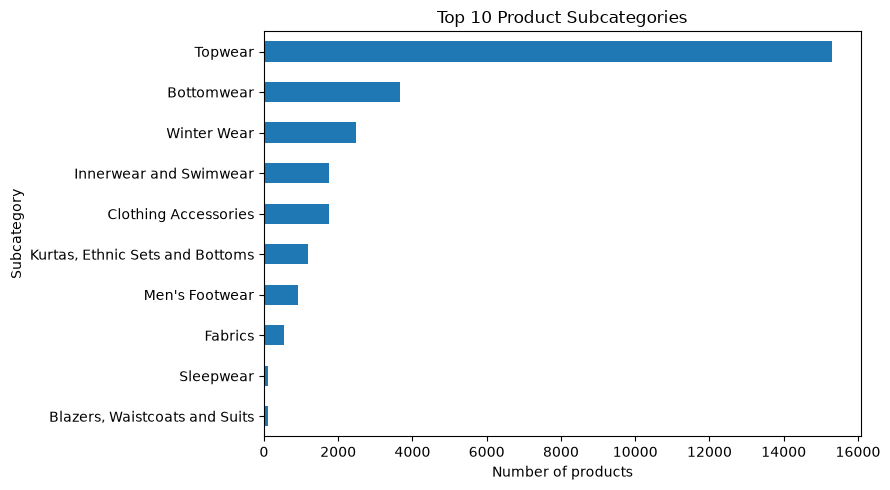

Top 10 brands:


brand
ECKO Unl        951
Free Authori    860
ARBO            806
REEB            802
Pu              798
True Bl         793
Keo             660
Amp             585
Black Beat      548
vims rai        503
Name: count, dtype: int64

In [11]:
# Most common product categories
print("Top 10 categories:")
display(df["category"].value_counts().head(10))

# Most common subcategories
print("Top 10 subcategories:")
display(df["sub_category"].value_counts().head(10))

# Plot the most common subcategories
top_subcategories = df["sub_category"].value_counts().head(10)

top_subcategories.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Top 10 Product Subcategories")
plt.xlabel("Number of products")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.show()

print("Top 10 brands:")
display(df["brand"].value_counts().head(10))

In [12]:
%pip install nltk

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import html
import nltk
import re

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import RegexpTokenizer

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\fronk\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [14]:
# English stop words
stop_words = set(stopwords.words("english"))

# Preserve words that may be important for product searches
important_words = {"men", "women", "no", "not", "nor"}
stop_words -= important_words

# Stemmer
stemmer = PorterStemmer()

In [15]:
def preprocess_text(text):
    if not isinstance(text, str) or not text.strip():
        return []

    # 1. HTML unescaping and stripping tags (Bonus cleaning)
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)

    # 2. Lowercase
    text = text.lower()

    # 3. Tokenize and remove punctuation
    tokens = re.findall(r"\b[a-z0-9]+\b", text)

    # 4. Remove stop words
    filtered_tokens = [t for t in tokens if t not in stop_words]

    # 5. Apply stemming
    stemmed_tokens = [stemmer.stem(t) for t in filtered_tokens]

    return stemmed_tokens

In [ ]:
# Flatten nested product_details list into a single string
df["product_details_text"] = df["product_details"].apply(
    flatten_product_details
)

In [18]:
# Apply preprocessing to the title and description columns

df["title_processed"] = df["title"].apply(preprocess_text)

df["description_processed"] = (df["description"].apply(preprocess_text))

display(df[["title", "title_processed", "description", "description_processed"]].head(10))

,title,title_processed,description,description_processed
0,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
1,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
2,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
3,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
4,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
5,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
6,Solid Women Dark Blue Track Pants,"[solid, women, dark, blue, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
7,Solid Women Beige Track Pants,"[solid, women, beig, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
8,Solid Women Black Track Pants,"[solid, women, black, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
9,Solid Men Grey Track Pants,"[solid, men, grey, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."


In [19]:
# Apply preprocessing to remaining categorical and text fields
other_fields = [
    "brand",
    "category",
    "sub_category",
    "seller",
    "product_details_text",
]

for field in other_fields:
    target_col = (
        "product_details_processed"
        if field == "product_details_text"
        else f"{field}_processed"
    )
    df[target_col] = df[field].apply(preprocess_text)

# Display sample of processed categorical fields
display(
    df[
        [
            "pid",
            "brand_processed",
            "category_processed",
            "sub_category_processed",
            "product_details_processed",
        ]
    ].head(5)
)

,pid,brand_processed,category_processed,sub_category_processed,product_details_processed
0,TKPFCZ9EA7H5FYZH,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo2, closur, elast, pocke..."
1,TKPFCZ9EJZV2UVRZ,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005blue, closur, drawstr, elast..."
2,TKPFCZ9EHFCY5Z4Y,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo4, closur, elast, pocke..."
3,TKPFCZ9ESZZ7YWEF,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo3, closur, elast, pocke..."
4,TKPFCZ9EVXKBSUD7,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo1, closur, drawstr, ela..."


In [20]:
test_queries = [
    "women full sleeve sweatshirt cotton",
    "men slim jeans blue",
]

print("--- Preprocessing Test on Sample Validation Queries ---")
for query in test_queries:
    print(f"Query:     '{query}'")
    print(f"Processed: {preprocess_text(query)}\n")

--- Preprocessing Test on Sample Validation Queries ---
Query:     'women full sleeve sweatshirt cotton'
Processed: ['women', 'full', 'sleev', 'sweatshirt', 'cotton']

Query:     'men slim jeans blue'
Processed: ['men', 'slim', 'jean', 'blue']



In [21]:
# Define the dictionary of separate tokenized fields per PID
separate_fields_corpus = {
    row["pid"]: {
        "title": row["title_processed"],
        "description": row["description_processed"],
        "brand": row["brand_processed"],
        "category": row["category_processed"],
        "sub_category": row["sub_category_processed"],
        "seller": row["seller_processed"],
        "product_details": row["product_details_processed"],
    }
    for _, row in df.iterrows()
}

# Display separate field tokens for a sample PID
sample_pid = df["pid"].iloc[0]
print(
    f"--- Separate Field Token Representation for Sample PID: {sample_pid} ---"
)
for field_name, tokens in separate_fields_corpus[sample_pid].items():
    print(f"{field_name.rjust(18)}: {tokens[:10]}")

--- Separate Field Token Representation for Sample PID: TKPFCZ9EA7H5FYZH ---
             title: ['solid', 'women', 'multicolor', 'track', 'pant']
       description: ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look']
             brand: ['york']
          category: ['cloth', 'accessori']
      sub_category: ['bottomwear']
            seller: ['shyam', 'enterpris']
   product_details: ['style', 'code', '1005combo2', 'closur', 'elast', 'pocket', 'side', 'pocket', 'fabric', 'cotton']


In [22]:
# Ensure Boolean type for out_of_stock
df["out_of_stock_bool"] = df["out_of_stock"].astype(bool)

# Build numerical/boolean metadata store keyed by PID
metadata_store = {
    row["pid"]: {
        "out_of_stock": row["out_of_stock_bool"],
        "selling_price": row["selling_price_num"],
        "actual_price": row["actual_price_num"],
        "discount_percent": row["discount_num"],
        "average_rating": row["average_rating_num"],
    }
    for _, row in df.iterrows()
}


def filter_products(
    max_price=None,
    min_rating=None,
    in_stock_only=True,
    min_discount=None,
):
    """Filters product PIDs based on structured numerical/boolean metadata criteria."""
    matching_pids = []
    for pid, meta in metadata_store.items():
        if in_stock_only and meta["out_of_stock"]:
            continue
        if (
            max_price is not None
            and pd.notna(meta["selling_price"])
            and meta["selling_price"] > max_price
        ):
            continue
        if (
            min_rating is not None
            and pd.notna(meta["average_rating"])
            and meta["average_rating"] < min_rating
        ):
            continue
        if (
            min_discount is not None
            and pd.notna(meta["discount_percent"])
            and meta["discount_percent"] < min_discount
        ):
            continue
        matching_pids.append(pid)
    return matching_pids


# Test metadata range filtering query
filtered_pids = filter_products(
    max_price=1000, min_rating=4.0, in_stock_only=True, min_discount=50.0
)
print(f"Total products in dataset: {len(df)}")
print(
    f"Products matching filter (Price <= 1000, Rating >= 4.0, Discount >= 50%, In Stock): {len(filtered_pids)}"
)

# Display sample metadata from the store
sample_pid = df["pid"].iloc[0]
print(f"\n--- Metadata Store Sample for PID: {sample_pid} ---")
print(metadata_store[sample_pid])

Total products in dataset: 28080
Products matching filter (Price <= 1000, Rating >= 4.0, Discount >= 50%, In Stock): 4781

--- Metadata Store Sample for PID: TKPFCZ9EA7H5FYZH ---
{'out_of_stock': False, 'selling_price': 921.0, 'actual_price': 2999.0, 'discount_percent': 69.0, 'average_rating': 3.9}
